# TP 5 – PAC-Bayes for majority votes: certify, then learn – Solutions

Last of five practical sessions (1: protocol, 2: bagging, 3: boosting, 4 and 5: PAC-Bayes). This session follows Sections 15 to 17 of the lecture notes. Bagging, random forests and boosting all output a majority vote; TP 4 certified the Gibbs classifier, which draws one voter at random, and we now certify the *vote* itself. We first relate the two with the first-order bound and see that it ignores how the errors of the voters are correlated; the joint error and the disagreement of pairs of voters then give the tandem bound, which we study on voters whose correlation we control. We then certify the random forest of the running example of the notes *without any test set*, with its out-of-bag examples, and we finally *learn* the weights of the forest by minimizing a bound: we derive the self-bounding algorithm of Section 17 step by step, implement it, and see why the bound to minimize must take the diversity of the voters into account. The session lasts **three hours**; Part 5 contains the difficult questions. All the numbers and figures of these solutions are produced by the code of this notebook (one function per part, about one minute in total). Unless stated otherwise, $\delta=0.05$.

*Statistical Supervised Machine Learning – Master MIASHS & MALIA. Run the cells in order, from the folder of this notebook (it uses `../common` and `../data`). Each part: the statement, the code, then the solutions with the tables and figures produced by the code.*

**Notation (Section 15).** $\mathcal{H}$ is a finite set of voters $h:\mathcal X\to\{-1,+1\}$ and $Q$ a distribution on $\mathcal{H}$. For an example $(x,y)$, $W_Q(x,y)=\sum_hQ(h)\mathbb{1}\left[h(x)\neq y\right]$ is the $Q$-weighted proportion of voters that err (Definition 15.1). We use

-   the **Gibbs risk** $R_{\mathcal{D}}(G_{Q})=\mathbb{E}[W_Q]=\sum_hQ(h)R_{\mathcal{D}}(h)$ and the risk of the **majority vote** $R_{\mathcal{D}}(B_{Q})=\mathbb{P}\big(B_{Q}(X)\neq Y\big)$, where $B_{Q}(x)=\operatorname{sign}\big(\sum_hQ(h)h(x)\big)$ (ties counted as errors);

-   the **joint error** $e_{\mathcal{D}}(Q)=\sum_{h,h'}Q(h)Q(h')\,\mathbb{P}\big(h(X)\neq Y,\,h'(X)\neq Y\big)$ and the **disagreement** $d_{\mathcal{D}}(Q)=\sum_{h,h'}Q(h)Q(h')\,\mathbb{P}\big(h(X)\neq h'(X)\big)$ (Definition 15.4).

The empirical versions are obtained by replacing $\mathcal{D}$ by a sample. As in TP 4, $\overline{\operatorname{kl}}^{-1}(q,\varepsilon)$ is the upper inverse of the binary kl, and $\delta=0.05$.

> **Good practice.** Store the predictions of the voters on a sample in a matrix `V` of shape (voters, examples) and the errors in `E = (V != y)`. Then the empirical risks are `E.mean(1)`, the matrix of empirical joint errors is `E @ E.T / n`, the Gibbs risk of $Q$ is `Q @ L` and its joint error `Q @ Lt @ Q`.

## Setup

In [1]:
import os, sys, time, warnings
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from scipy.stats import norm, binom
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.datasets import load_digits
warnings.filterwarnings("ignore")

HERE = os.path.dirname(os.path.abspath(__file__)) if "__file__" in globals() else os.getcwd()
sys.path.insert(0, os.path.join(HERE, "..", "common"))
from tptools import load, kl_inv_upper, show_table as _show_rows
from pbtools import kl_div, c_bound, fo_bound, tnd_bound, tandem_fixed_point

DELTA = 0.05
C1, C2, C3, C4, C5, GREY = "#1f5f99", "#c8553d", "#2a9d8f", "#e9a13b", "#6c4f9c", "#8c8c8c"
plt.rcParams.update({"font.family": "serif", "mathtext.fontset": "cm", "font.size": 9,
                     "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
                     "savefig.bbox": "tight", "figure.dpi": 120})

# column headers of the tables
HEADERS = {
    'p1_vote': ['$\\lambda$', '$R_{\\mathcal{D}}(G_Q)$', '$R_{\\mathcal{D}}(B_Q)$', '$2R_{\\mathcal{D}}(G_Q)$', "$2\\times$Seeger's bound"],
    'p2_condorcet': ['$n$', '$p=0.3$, $c=0$', 'bound $e^{-2n(1/2-p)^2}$', '$p=0.3$, $c=0.3$', '$p=0.45$, $c=0$', 'bound $e^{-2n(1/2-p)^2}$', '$p=0.45$, $c=0.3$'],
    'p2_check': ['', 'Gibbs risk', 'joint error $e$', 'disagreement $d$', 'risk of the vote'],
    'p2_bounds': ['$p$', '$c$', 'risk of the vote', 'first order $2R(G_Q)$', 'tandem $4e(Q)$'],
    'p3_oob': ['', 'simulated', 'theory'],
    'p3_cert': ['', 'value'],
    'p4_gibbs': ['$\\lambda$', 'Gibbs posterior – FO certificate', 'eff. trees', 'vote (test)', 'tandem algorithm – tandem certificate', 'eff. trees', 'vote (test)', 'iterations'],
    'p4_check': ['$\\lambda$', 'max $\\vert Q_{\\text{mine}}-Q_{\\text{pbtools}}\\vert$'],
    'p4_datasets': ['data', 'uniform – vote (test)', 'uniform – tandem cert.', 'Gibbs posterior – vote (test)', 'Gibbs posterior – FO cert.', 'Gibbs posterior – eff. trees', 'tandem algorithm – vote (test)', 'tandem algorithm – tandem cert.', 'tandem algorithm – eff. trees'],
    'p5_tight': ['$n$', '$r$', '$R_{\\mathcal{D}}(G_Q)$', '$e(Q)$', '$R_{\\mathcal{D}}(B_Q)$', 'ratio', '$4e(Q)$'],
    'p5_linear': ['', 'value'],
}

TABLES, FIGURES = {}, {}


def keep_table(name, rows):
    """Keep the rows of a table ('a & b & c', math between $) to show it later with show_table(name)."""
    TABLES[name] = rows


def keep_figure(fig, name):
    """Keep a figure to show it later with show_figure(name)."""
    FIGURES[name] = fig
    plt.close(fig)


def show_table(name):
    _show_rows(TABLES[name], HEADERS.get(name))


def show_figure(name):
    from IPython.display import display
    display(FIGURES[name])

## Part 1 – Gibbs classifier, majority vote and the first-order bound (Sections 15.1–15.2)

1.  Show that $B_{Q}$ errs on $(x,y)$ if and only if $W_Q(x,y)\geq\frac12$, and deduce from Markov's inequality (Lemma 13.1) that $R_{\mathcal{D}}(B_{Q})\leq2R_{\mathcal{D}}(G_{Q})$ (Proposition 15.2).\
    Combine it with Seeger's bound (TP 4) to obtain a certificate for the vote.

2.  On the toy problem of TP 4 (one sample, $m=100$, uniform prior on the $102$ thresholds), compute for the Gibbs posteriors $Q_\lambda$, $\lambda\in\{10,30,100,300,3000\}$: the true Gibbs risk, the true risk of the vote (on a fine grid of $[0,1]$, since it can be computed exactly), the oracle bound $2R_{\mathcal{D}}(G_{Q})$ and the PAC-Bayesian first-order bound.\
    Comment.

In [2]:
THETA, ETA = 0.37, 0.15
T = np.round(np.arange(0, 1.0001, 0.02), 2)
TT = np.r_[T, T]; SS = np.r_[np.ones(51), -np.ones(51)]; K = len(TT)
PRIOR = np.ones(K) / K
XG = (np.arange(20000) + 0.5) / 20000                    # fine grid of [0,1]: exact risks of the votes


def true_risks():
    r = ETA + (1 - 2 * ETA) * np.abs(TT - THETA)
    return np.where(SS > 0, r, 1 - r)


def sample(m, rng):
    x = rng.rand(m); y = np.where(x > THETA, 1, -1)
    return x, y * np.where(rng.rand(m) < ETA, -1, 1)


def emp_risks(x, y):
    pred = SS[:, None] * np.where(x[None, :] > TT[:, None], 1, -1)
    return np.mean(pred != y[None, :], axis=1)


def gibbs_posterior(r, lam, P=PRIOR):
    """Proposition 14.6: Q_lambda(h) proportional to P(h) exp(-lambda r(h))."""
    a = np.log(P) - lam * r; a -= a.max(); Q = np.exp(a)
    return Q / Q.sum()


def seeger(gibbs_emp, kl_qp, m):
    return kl_inv_upper(gibbs_emp, (kl_qp + np.log(2 * np.sqrt(m) / DELTA)) / m)


def vote_true_risk(Q):
    v = Q @ (SS[:, None] * np.where(XG[None, :] > TT[:, None], 1, -1))
    pred = np.where(v > 0, 1, -1); clean = np.where(XG > THETA, 1, -1)   # (no tie on the grid for these posteriors)
    return float(np.mean(np.where(pred == clean, ETA, 1 - ETA)))


def part1():
    print("Part 1")
    R = true_risks(); rng = np.random.RandomState(0); m = 100
    x, y = sample(m, rng); r = emp_risks(x, y); rows = []
    for lam in [10, 30, 100, 300, 3000]:
        Q = gibbs_posterior(r, lam); g = Q @ R; sb = seeger(Q @ r, kl_div(Q, PRIOR), m)
        rows.append(f"{lam:g} & {g:.3f} & {vote_true_risk(Q):.3f} & {2 * g:.3f} & {min(1, 2 * sb):.3f}")
    keep_table("p1_vote", rows)

In [3]:
part1()

Part 1


### Solution

**1.** With labels and votes in $\{-1,+1\}$, $B_{Q}(x)\neq y$ means that the voters predicting $-y$ have at least half of the weight (ties are counted as errors), i.e. $W_Q(x,y)\geq\frac12$. As $W_Q\geq0$, Markov's inequality gives $$R_{\mathcal{D}}(B_{Q})=\mathbb{P}\big(W_Q\geq\tfrac12\big)\leq\frac{\mathbb{E}W_Q}{1/2}=2R_{\mathcal{D}}(G_{Q}).$$ With Seeger's bound, with probability at least $1-\delta$, for all $Q$, $R_{\mathcal{D}}(B_{Q})\leq2\overline{\operatorname{kl}}^{-1}\big(\widehat{R}_{S}(G_{Q}),\frac{\operatorname{KL}(Q\|P)+\ln(2\sqrt m/\delta)}m\big)$ (equation (15.3) of the notes).

**2.**

In [4]:
show_table("p1_vote")

| $\lambda$ | $R_{\mathcal{D}}(G_Q)$ | $R_{\mathcal{D}}(B_Q)$ | $2R_{\mathcal{D}}(G_Q)$ | $2\times$Seeger's bound |
|:---:|:---:|:---:|:---:|:---:|
| 10 | 0.243 | 0.157 | 0.485 | 0.754 |
| 30 | 0.186 | 0.157 | 0.373 | 0.635 |
| 100 | 0.163 | 0.157 | 0.325 | 0.598 |
| 300 | 0.158 | 0.157 | 0.315 | 0.603 |
| 3000 | 0.157 | 0.157 | 0.314 | 0.606 |

The vote is always as good as the best threshold of the class ($0.157$), even for a small $\lambda$, when the Gibbs classifier is poor ($0.243$ for $\lambda=10$): averaging the thresholds around the optimum cancels their errors. The first-order bound is valid but loose: the factor $2$ comes from Markov's inequality, which ignores the fact that the voters do not all err on the same points. Certified this way, the vote looks four times worse than it is ($\approx0.60$).

## Part 2 – Condorcet, joint error, disagreement and the tandem bound (Sections 15.3–15.5)

We consider $n=25$ voters with uniform weights and the following model: voter $i$ errs on an example when $\sqrt c\,Z+\sqrt{1-c}\,\xi_i<\Phi^{-1}(p)$, where $Z$ (the "difficulty" of the example) and $\xi_1,\dots,\xi_n$ are independent $\mathcal N(0,1)$ and $\Phi$ is the c.d.f. of $\mathcal N(0,1)$. Every voter has risk $p$, and $c\in[0,1)$ tunes the correlation between their errors ($c=0$: independent errors). Given $Z$, the errors are independent Bernoulli variables of parameter $\pi(Z)=\Phi\big((\Phi^{-1}(p)-\sqrt cZ)/\sqrt{1-c}\big)$, so all the exact quantities below can be computed by a one-dimensional integral over $Z$.

1.  **Condorcet.** For $c=0$, prove Proposition 15.3: $R_{\mathcal{D}}(B_{Q})\leq e^{-2n(\frac12-p)^2}$.\
    Compute the exact risk of the vote for $n\in\{1,5,25,101,1001\}$, $p\in\{0.3,0.45\}$, $c\in\{0,0.3\}$, compare it with this bound when $c=0$, and give its limit when $n\to\infty$.\
    Conclude.

2.  **Identity.** Show that $R_{\mathcal{D}}(G_{Q})=e_{\mathcal{D}}(Q)+\frac12d_{\mathcal{D}}(Q)$ (Proposition 15.5; hint: for two voters, $\mathbb{1}\left[h\neq y\right]+\mathbb{1}\left[h'\neq y\right]=2\,\mathbb{1}\left[h\neq y,\,h'\neq y\right]+\mathbb{1}\left[h\neq h'\right]$), and that $e_{\mathcal{D}}(Q)=\mathbb{E}[W_Q^2]$.

3.  **Tandem bound.** Show that $R_{\mathcal{D}}(B_{Q})\leq\mathbb{P}(W_Q^2\geq\frac14)\leq4e_{\mathcal{D}}(Q)$ (Proposition 15.6).

4.  Simulate the errors of the $25$ voters on $m=20\,000$ examples for $p=0.3$, $c=0.3$.\
    Compute the Gibbs risk, the joint error and the disagreement (a) from $W_Q$, (b) from the pairs of voters (all the $n^2$ ordered pairs, including $h=h'$), and the risk of the vote.\
    Compare with the exact values.

5.  For $p\in\{0.2,0.35,0.45\}$ and $c\in[0,0.98]$, plot the risk of the vote and the two oracle bounds: first-order $2R_{\mathcal{D}}(G_{Q})$ and tandem $4e_{\mathcal{D}}(Q)$.\
    When is the tandem bound better than the first-order bound? What does it say about diversity?

In [5]:
def simulate_errors(n, m, p, c, rng):
    """(n, m) matrix of errors: voter i errs when sqrt(c) Z + sqrt(1-c) xi_i < Phi^{-1}(p)."""
    Z = rng.randn(m, 1); xi = rng.randn(m, n)
    return (np.sqrt(c) * Z + np.sqrt(1 - c) * xi < norm.ppf(p)).astype(float).T


ZG = np.linspace(-9, 9, 40001); ZW = norm.pdf(ZG) * (ZG[1] - ZG[0])


def exact_quantities(n, p, c):
    """Exact Gibbs risk, joint error, disagreement and risk of the uniform vote of n voters (n odd):
    given Z, the n errors are i.i.d. Bernoulli(pi(Z))."""
    pi_z = np.full_like(ZG, p) if c <= 0 else norm.cdf((norm.ppf(p) - np.sqrt(c) * ZG) / np.sqrt(1 - c))
    gibbs = ZW @ pi_z
    joint = ZW @ (pi_z / n + (n - 1) / n * pi_z ** 2)
    dis = 2 * (gibbs - joint)
    mv = ZW @ binom.sf((n + 1) // 2 - 1, n, pi_z)
    return gibbs, joint, dis, mv


def part2():
    print("Part 2")
    rows = []
    for nv in [1, 5, 25, 101, 1001]:
        cells = []
        for p in [0.3, 0.45]:
            cells += [exact_quantities(nv, p, 0.0)[3], np.exp(-2 * nv * (0.5 - p) ** 2), exact_quantities(nv, p, 0.3)[3]]
        rows.append(f"{nv} & " + " & ".join(f"{v:.3f}" for v in cells))
    rows.append("--- $n\\to\\infty$ & 0 & 0 & " + f"{norm.cdf(norm.ppf(0.3) / np.sqrt(0.3)):.3f} & 0 & 0 & {norm.cdf(norm.ppf(0.45) / np.sqrt(0.3)):.3f}")
    keep_table("p2_condorcet", rows)
    rng = np.random.RandomState(0); n = 25
    E = simulate_errors(n, 20000, 0.3, 0.3, rng); W = E.mean(0); V = 1 - 2 * E
    dis_pairs = np.mean([np.mean(V[i] != V[j]) for i in range(n) for j in range(n)])
    joint_pairs = np.mean([np.mean(E[i] * E[j]) for i in range(n) for j in range(n)])
    ex = exact_quantities(n, 0.3, 0.3)
    keep_table("p2_check", [
        f"simulation, from $W_Q$ & {W.mean():.4f} & {np.mean(W ** 2):.4f} & {2 * (W.mean() - np.mean(W ** 2)):.4f} & {np.mean(W >= 0.5):.4f}",
        f"simulation, from the pairs & -- & {joint_pairs:.4f} & {dis_pairs:.4f} & --",
        f"exact & {ex[0]:.4f} & {ex[1]:.4f} & {ex[2]:.4f} & {ex[3]:.4f}"])
    cs = np.linspace(0, 0.98, 99)
    fig, axes = plt.subplots(1, 3, figsize=(7.6, 2.5), sharey=True); rows = []
    for ax, p in zip(axes, [0.2, 0.35, 0.45]):
        cur = {k: [] for k in ["mv", "fo", "tnd"]}
        for c in cs:
            g, e, d, mv = exact_quantities(n, p, c)
            cur["mv"].append(mv); cur["fo"].append(2 * g); cur["tnd"].append(4 * e)
        cur = {k: np.minimum(np.array(v), 1) for k, v in cur.items()}
        ax.plot(cs, cur["mv"], color="k", lw=1.8, label="risk of the vote")
        ax.plot(cs, cur["fo"], color=C1, label=r"first order $2R(G_Q)$")
        ax.plot(cs, cur["tnd"], color=C2, label=r"tandem $4e(Q)$")
        ax.axhline(p, color=GREY, lw=0.8, ls=":", label="risk of one voter $p$")
        ax.set_title(rf"$p={p}$, $n={n}$", fontsize=9); ax.set_xlabel(r"correlation $c$"); ax.set_ylim(0, 1.0)
        for c in [0.0, 0.1, 0.5, 0.9]:
            j = int(round(c * 100))
            rows.append(f"{p} & {c:.1f} & {cur['mv'][j]:.3f} & {cur['fo'][j]:.3f} & {cur['tnd'][j]:.3f}")
    axes[0].set_ylabel("risk / bound")
    axes[1].legend(fontsize=7, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.27))
    keep_figure(fig, "tp5_correlation")
    keep_table("p2_bounds", rows)

In [6]:
part2()

Part 2


### Solution

**1.** With $c=0$, on a random example the errors of the $n$ voters are independent Bernoulli variables of mean $p$, and $W_Q=\frac1n\sum_t\mathbb{1}\left[h_t(x)\neq y\right]$ is their average. Hoeffding's inequality (Theorem 13.2, applied to the upper tail) gives $R_{\mathcal{D}}(B_{Q})=\mathbb{P}(W_Q\geq\frac12)=\mathbb{P}\big(W_Q-p\geq\frac12-p\big)\leq e^{-2n(\frac12-p)^2}$. Exact risk of the vote of $n$ voters, and the bound of Proposition 15.3 for $c=0$:

In [7]:
show_table("p2_condorcet")

| $n$ | $p=0.3$, $c=0$ | bound $e^{-2n(1/2-p)^2}$ | $p=0.3$, $c=0.3$ | $p=0.45$, $c=0$ | bound $e^{-2n(1/2-p)^2}$ | $p=0.45$, $c=0.3$ |
|:---:|:---:|:---:|:---:|:---:|:---:|:---:|
| 1 | 0.300 | 0.923 | 0.300 | 0.450 | 0.995 | 0.450 |
| 5 | 0.163 | 0.670 | 0.229 | 0.407 | 0.975 | 0.429 |
| 25 | 0.017 | 0.135 | 0.185 | 0.306 | 0.882 | 0.415 |
| 101 | 0.000 | 0.000 | 0.173 | 0.156 | 0.604 | 0.411 |
| 1001 | 0.000 | 0.000 | 0.170 | 0.001 | 0.007 | 0.409 |
| $n\to\infty$ | 0 | 0 | 0.169 | 0 | 0 | 0.409 |

With independent voters the risk of the vote tends to $0$ for any $p<\frac12$, as the bound predicts (the bound is valid but loose for small $n$, and very slow when $p$ is close to $\frac12$: $n=101$ voters of risk $0.45$ still give $0.156$). With correlated voters ($c=0.3$) the risk tends to $\mathbb{P}(\pi(Z)>\frac12)>0$ ($0.169$ and $0.409$): the examples that are difficult for every voter are lost whatever the number of voters. Adding voters helps only if they are *diverse*.

**2.** The hint is checked on the four cases (both right: $0=0$; both wrong: $2=2$; exactly one wrong: $1=1$). Taking the expectation over $h,h'\sim Q$ independently and over $(X,Y)$ gives $2R_{\mathcal{D}}(G_{Q})=2e_{\mathcal{D}}(Q)+d_{\mathcal{D}}(Q)$. Given $(x,y)$, two independent voters both err with probability $W_Q(x,y)^2$, so $e_{\mathcal{D}}(Q)=\mathbb{E}[W_Q^2]$.

**3.** $B_{Q}$ errs iff $W_Q\geq\frac12$, i.e. $W_Q^2\geq\frac14$ (since $W_Q\geq0$), and Markov's inequality applied to $W_Q^2$ gives $\mathbb{P}(W_Q^2\geq\frac14)\leq4\mathbb{E}[W_Q^2]=4e_{\mathcal{D}}(Q)$. Since $e_{\mathcal{D}}(Q)\leq R_{\mathcal{D}}(G_{Q})$ (as $W_Q^2\leq W_Q$), the tandem bound can be better or worse than the first-order bound: it is better when $e_{\mathcal{D}}(Q)<\frac12R_{\mathcal{D}}(G_{Q})$, i.e. by the identity, when $d_{\mathcal{D}}(Q)>R_{\mathcal{D}}(G_{Q})$: when the voters disagree more than they err.

**4.**

In [8]:
show_table("p2_check")

|  | Gibbs risk | joint error $e$ | disagreement $d$ | risk of the vote |
|:---:|:---:|:---:|:---:|:---:|
| simulation, from $W_Q$ | 0.2993 | 0.1337 | 0.3312 | 0.1838 |
| simulation, from the pairs | – | 0.1337 | 0.3312 | – |
| exact | 0.3000 | 0.1350 | 0.3300 | 0.1854 |

The two ways of computing $e$ and $d$ coincide (they are the same quantity, $\mathbb{E}W_Q^2$ and $2(\mathbb{E}W_Q-\mathbb{E}W_Q^2)$), and agree with the exact values up to the simulation error.

**5.**

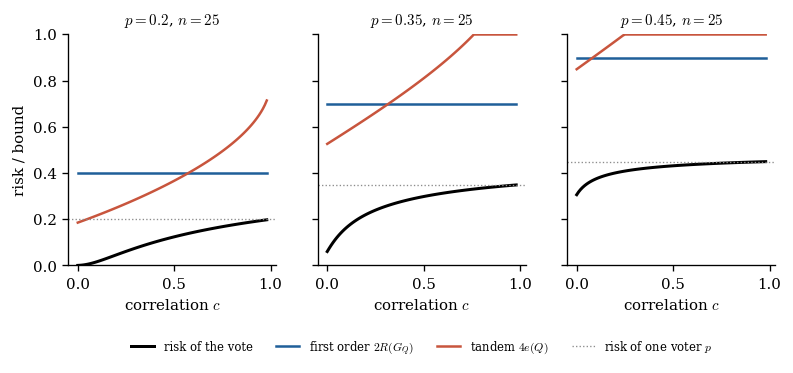

In [9]:
show_figure("tp5_correlation")

In [10]:
show_table("p2_bounds")

| $p$ | $c$ | risk of the vote | first order $2R(G_Q)$ | tandem $4e(Q)$ |
|:---:|:---:|:---:|:---:|:---:|
| 0.2 | 0.0 | 0.000 | 0.400 | 0.186 |
| 0.2 | 0.1 | 0.016 | 0.400 | 0.217 |
| 0.2 | 0.5 | 0.124 | 0.400 | 0.367 |
| 0.2 | 0.9 | 0.188 | 0.400 | 0.608 |
| 0.35 | 0.0 | 0.060 | 0.700 | 0.526 |
| 0.35 | 0.1 | 0.164 | 0.700 | 0.580 |
| 0.35 | 0.5 | 0.298 | 0.700 | 0.810 |
| 0.35 | 0.9 | 0.343 | 0.700 | 1.000 |
| 0.45 | 0.0 | 0.306 | 0.900 | 0.850 |
| 0.45 | 0.1 | 0.375 | 0.900 | 0.910 |
| 0.45 | 0.5 | 0.432 | 0.900 | 1.000 |
| 0.45 | 0.9 | 0.447 | 0.900 | 1.000 |

When the voters are independent ($c=0$) the vote is far better than each voter (risk $0$ for $p=0.2$, $0.06$ for $p=0.35$), and the tandem bound captures part of this improvement ($0.19$ and $0.53$), while the first-order bound is useless ($2p$). When $c$ grows the voters err together, the vote gets closer to a single voter, the joint error increases and the tandem bound degrades. It is better than the first-order bound exactly when $d_{\mathcal{D}}(Q)>R_{\mathcal{D}}(G_{Q})$: for $p=0.2$ up to $c\approx0.55$, for $p=0.35$ up to $c\approx0.3$, and almost never for $p=0.45$ (weak voters). The tandem bound rewards diversity, but only for voters that are individually good enough: this is the lesson of Section 15, and the reason why it is a good objective for learning a vote (Part 4).

## Part 3 – Certifying a random forest without a test set (Sections 15.5 and 16.2)

We use the running example of Part IV of the notes: `digits`, task "is the digit smaller than $5$?", split with `train_test_split(X, y, test_size=0.3, random_state=0)` ($1257$ training and $540$ test digits), and a forest of $100$ trees, each learned with `DecisionTreeClassifier(max_features="sqrt")` on a bootstrap sample of *half* the size of the training set. The prior $P$ is uniform on the *indices* $1,\dots,100$ of the trees, fixed before the forest is grown. Each tree $h_t$ is evaluated on its *out-of-bag* (OOB) examples $T_t$, the training examples that are not in its bootstrap sample.

1.  Write `grow_forest(Xtr, ytr, n_trees, frac, rng)` returning the trees and the boolean $100\times m$ matrix of the OOB examples.\
    Show that an example is out-of-bag for a given tree with probability $(1-\frac1m)^{m/2}\approx e^{-1/2}\approx61\%$, and for two given trees with probability $\approx e^{-1}\approx37\%$. Check it.

2.  Compute the OOB error $\hat L(h_t)$ of each tree on $T_t$, and the empirical joint error $\hat e(h_t,h_{t'})$ of each pair on $T_t\cap T_{t'}$; let $n_1=\min_t|T_t|$ and $m=\min_{t,t'}|T_t\cap T_{t'}|$.\
    For the uniform posterior $Q=P$, compute the first-order certificate $2\overline{\operatorname{kl}}^{-1}\big(\sum_tQ(h_t)\hat L(h_t),\frac{\operatorname{KL}(Q\|P)+\ln(2\sqrt{n_1}/\delta)}{n_1}\big)$ and the tandem certificate $4\overline{\operatorname{kl}}^{-1}\big(\hat e(Q),\frac{2\operatorname{KL}(Q\|P)+\ln(2\sqrt{m}/\delta)}{m}\big)$ (equations (15.3) and (15.4), with the OOB replacements of Section 16.2).

3.  Compute on the test set the risk of the vote, the Gibbs risk, the joint error and the disagreement, and the kl test-set bound of the vote (Theorem 13.5).\
    Compare the three certificates. Which ones need a test set?

4.  Why are the OOB certificates valid, although every training example has been used to grow some of the trees?\
    Why must $m$ be the size of the *smallest* common OOB set?

In [11]:
def grow_forest(Xtr, ytr, n_trees=100, frac=0.5, rng=None):
    """Trees learned on bootstrap samples of size frac * m (sqrt(d) features at each node),
    and the boolean (n_trees, m) matrix of their out-of-bag examples."""
    rng = rng or np.random.RandomState(0); m = len(ytr); trees, oob = [], []
    for t in range(n_trees):
        idx = rng.randint(0, m, int(frac * m))
        mask = np.ones(m, bool); mask[idx] = False
        trees.append(DecisionTreeClassifier(max_features="sqrt", random_state=rng.randint(1 << 30)).fit(Xtr[idx], ytr[idx]))
        oob.append(mask)
    return trees, np.array(oob)


def oob_statistics(trees, oob, Xtr, ytr):
    """OOB errors of the trees (vector L, smallest OOB set n1) and OOB joint errors of the pairs
    (matrix E, smallest common OOB set m)."""
    V = np.array([t.predict(Xtr) for t in trees])
    Err = ((V != ytr[None, :]) & oob).astype(float); O = oob.astype(float)
    L = Err.sum(1) / O.sum(1); n1 = int(O.sum(1).min())
    both = O @ O.T; E = (Err @ Err.T) / np.maximum(both, 1); m = int(both.min())
    return L, n1, E, m


def digits_data():
    X, y = load_digits(return_X_y=True); y = np.where(y >= 5, 1, -1)
    return train_test_split(X, y, test_size=0.3, random_state=0)       # Xtr, Xte, ytr, yte


def part3():
    print("Part 3")
    Xtr, Xte, ytr, yte = digits_data(); m_tr = len(ytr)
    trees, oob = grow_forest(Xtr, ytr, 100, 0.5, np.random.RandomState(0))
    O = oob.astype(float)
    keep_table("p3_oob", [f"OOB for one tree & {O.mean():.3f} & {(1 - 1 / m_tr) ** (m_tr // 2):.3f}",
                          f"OOB for two trees & {np.mean([np.mean(oob[i] & oob[j]) for i in range(100) for j in range(i + 1, 100)]):.3f} & {(1 - 1 / m_tr) ** (2 * (m_tr // 2)):.3f}"])
    L, n1, E, m = oob_statistics(trees, oob, Xtr, ytr); P = np.ones(100) / 100
    Vte = np.array([t.predict(Xte) for t in trees]); Ete = (Vte != yte[None, :]).astype(float)
    W = P @ Ete; vote = np.mean(W >= 0.5)
    test_kl = kl_inv_upper(vote, np.log(1 / DELTA) / len(yte))
    keep_table("p3_cert", [
        f"$n_1$ (smallest OOB set) & {n1}", f"$m$ (smallest common OOB set) & {m}",
        f"OOB Gibbs risk & {P @ L:.3f}", f"OOB joint error & {P @ E @ P:.3f}",
        f"first-order certificate (OOB) & {fo_bound(P, P, L, n1, DELTA):.3f}",
        f"tandem certificate (OOB) & {tnd_bound(P, P, E, m, DELTA):.3f}",
        f"--- test set: risk of the vote & {vote:.3f}", f"test set: Gibbs risk & {W.mean():.3f}",
        f"test set: joint error & {np.mean(W ** 2):.3f}", f"test set: disagreement & {np.mean(2 * W * (1 - W)):.3f}",
        f"kl test-set bound of the vote (Theorem 13.5, 540 test digits) & {test_kl:.3f}"])
    return dict(trees=trees, oob=oob, L=L, n1=n1, E=E, m=m, Vte=Vte, yte=yte)

In [12]:
F = part3()

Part 3


### Solution

**1.** A bootstrap sample of size $m/2$ draws $m/2$ indices with replacement; a given example is missed by one draw with probability $1-\frac1m$, hence by all of them with probability $(1-\frac1m)^{m/2}\approx e^{-1/2}\approx0.61$. The bootstrap samples of two trees are independent, so an example is out-of-bag for both with probability $(1-\frac1m)^{m}\approx e^{-1}\approx0.37$. Simulated proportions on the $1257$ training digits:

In [13]:
show_table("p3_oob")

|  | simulated | theory |
|:---:|:---:|:---:|
| OOB for one tree | 0.607 | 0.607 |
| OOB for two trees | 0.368 | 0.368 |

**2--3.** OOB quantities and certificates for the uniform weights, and the same quantities on the test set:

In [14]:
show_table("p3_cert")

|  | value |
|:---:|:---:|
| $n_1$ (smallest OOB set) | 747 |
| $m$ (smallest common OOB set) | 423 |
| OOB Gibbs risk | 0.174 |
| OOB joint error | 0.049 |
| first-order certificate (OOB) | 0.460 |
| tandem certificate (OOB) | 0.387 |
| test set: risk of the vote | 0.044 |
| test set: Gibbs risk | 0.190 |
| test set: joint error | 0.057 |
| test set: disagreement | 0.266 |
| kl test-set bound of the vote (Theorem 13.5, 540 test digits) | 0.070 |

We recover the numbers of the notes (Sections 13, 15 and 16). The forest errs on $4.4\%$ of the test digits. (The OOB error of a tree, $\hat L(h_t)$, is its empirical risk $\widehat{R}_S(h_t)$ computed on its OOB examples, and $\hat e(h_t,h_{t'})$ the empirical joint error $\widehat{e}_S$ of Section 15.5 computed on the common OOB examples.) The OOB certificates are valid but much larger: the first-order certificate pays the factor $2$ on a Gibbs risk of $0.17$ ($0.460$), the tandem certificate pays the factor $4$ on a joint error of $0.049$ ($0.387$): since the trees are diverse (disagreement $0.27$ larger than the Gibbs risk $0.19$, Part 2), the tandem certificate is the better one. The kl test-set bound on the vote ($0.070$; the notes report $0.069$, computed with the rounded error $0.044$) is much tighter, but it needs $540$ digits that were not used for training; the OOB certificates use none.

**4.** The prior is defined on the *indices* of the trees and fixed before the forest is grown, and each tree is evaluated only on examples it has not seen: from the point of view of tree $h_t$, its OOB examples are a fresh sample (Section 16.2). The same holds for a pair of trees on the examples that are OOB for both. The bounds are then applied with a sample size that must be valid for *every* tree (or pair): with fewer examples for some trees, their empirical errors are less reliable, and the safe choice is the smallest size $n_1=747$ (resp. $m=423$). Every training example is used both to grow some trees and to certify the others.

## Part 4 – Learning the weights of the forest: deriving a self-bounding algorithm (Sections 16.3 and 17)

Since the bounds hold for all posteriors $Q$ simultaneously, we may *choose* the weights of the $100$ trees by minimizing a bound on the OOB data, and keep the value of the bound as a certificate (self-bounding learning, Section 16.1). We follow the five steps of Section 17.1.

1.  **The first-order recipe.** With the bound of Theorem 14.4 applied to the OOB errors, the objective is $\sum_tQ(h_t)\hat L(h_t)+\frac{\operatorname{KL}(Q\|P)}{\lambda}$, minimized by the Gibbs posterior $Q_\lambda(h_t)\propto P(h_t)e^{-\lambda\hat L(h_t)}$ (Proposition 14.6).\
    For $\lambda\in\{1,2,4,\dots,4096\}$, compute its first-order certificate, its number of *effective trees* $1/\sum_tQ(h_t)^2$ and the test risk of its vote.\
    Comment.

2.  **The tandem objective.** Applying Theorem 14.4 to pairs of voters gives the linear tandem bound (Proposition 17.1). Show that, for a fixed $\lambda$, its terms that depend on $Q$ are $F_\lambda(Q)=\hat e(Q)+\frac2\lambda\operatorname{KL}(Q\|P)$.

3.  **The optimality condition.** With a Lagrange multiplier for the constraint $\sum_tQ(h_t)=1$ (Section 4.3), show that a minimizer $Q^\star$ of $F_\lambda$ with positive weights satisfies $Q^\star(h)\propto P(h)\,e^{-\lambda\hat e(h,Q^\star)}$, with $\hat e(h,Q)=\sum_{h'}Q(h')\hat e(h,h')$ (Proposition 17.2).\
    Interpret: how is a tree penalized, compared with the Gibbs posterior?

4.  **The algorithm.** Implement the damped fixed-point iterations of Algorithm 13 ($\alpha=0.1$) and check your function against `tandem_fixed_point` of `common/pbtools.py`.\
    For $\lambda\in\{1,2,4,\dots,4096\}$, compute the tandem certificate of the output, its number of effective trees and the test risk of its vote.\
    Plot the certificates and the test risks of the two algorithms against $\lambda$, and the weights of the trees against their OOB errors for the selected $\lambda$.

5.  Why may $\lambda$ be chosen by minimizing the kl certificate, without any union bound? Is the certificate still valid if the iterations are stopped before convergence?

6.  Apply the two algorithms (with $\lambda$ selected on the certificate) to `spambase`, `wdbc` and `australian` (split $70\%/30\%$, `random_state=0`, same forests).\
    Report, for the uniform weights and for the two learned posteriors, the certificate, the number of effective trees and the test risk of the vote.\
    Which bound is the right objective for learning a vote?

In [15]:
LAMBDAS = [2 ** j for j in range(13)]          # 1, 2, 4, ..., 4096


def eff(Q):
    return 1 / np.sum(Q ** 2)


def vote_risk(Q, Vte, yte):
    """Risk of the Q-weighted vote on the test set (ties counted as errors)."""
    return float(np.mean(yte * (Q @ Vte) <= 0))


def gibbs_oob(L, lam, P):
    a = np.log(P) - lam * L; a -= a.max(); Q = np.exp(a)
    return Q / Q.sum()


def my_tandem_algorithm(E, lam, P, alpha=0.1, n_iter=3000, tol=1e-9):
    """Algorithm 13: damped fixed-point iterations for Q(h) proportional to P(h) exp(-lam e(h, Q))."""
    Q = P.copy()
    for t in range(n_iter):
        s = E @ Q                                   # shared errors e(h, Q)
        T = P * np.exp(-lam * (s - s.min()))        # subtracting min(s) does not change T after normalization
        T = T / T.sum()
        Q_new = (1 - alpha) * Q + alpha * T
        if np.abs(Q_new - Q).max() < tol:
            return Q_new, t + 1
        Q = Q_new
    return Q, n_iter


def run_both(F, P):
    """Both algorithms on the grid of lambdas; returns the rows and the selected posteriors."""
    out = []
    for lam in LAMBDAS:
        Qg = gibbs_oob(F["L"], lam, P); Qt, it = my_tandem_algorithm(F["E"], lam, P)
        out.append(dict(lam=lam, Qg=Qg, fo=fo_bound(Qg, P, F["L"], F["n1"], DELTA), Qt=Qt, it=it,
                        tnd=tnd_bound(Qt, P, F["E"], F["m"], DELTA)))
    return out


def part4(F):
    print("Part 4")
    P = np.ones(100) / 100; out = run_both(F, P); Vte, yte = F["Vte"], F["yte"]
    keep_table("p4_check", [f"{lam} & {np.abs(my_tandem_algorithm(F['E'], lam, P)[0] - tandem_fixed_point(P, F['E'], lam)[0]).max():.1e}"
                            for lam in [16, 256, 4096]])
    rows = []
    for o in out:
        rows.append(f"{o['lam']} & {o['fo']:.3f} & {eff(o['Qg']):.1f} & {vote_risk(o['Qg'], Vte, yte):.3f} & "
                    f"{o['tnd']:.3f} & {eff(o['Qt']):.1f} & {vote_risk(o['Qt'], Vte, yte):.3f} & {o['it']}")
    ig = int(np.argmin([o["fo"] for o in out])); it_ = int(np.argmin([o["tnd"] for o in out]))
    rows.append(f"--- uniform weights & {fo_bound(P, P, F['L'], F['n1'], DELTA):.3f} & 100 & {vote_risk(P, Vte, yte):.3f} & "
                f"{tnd_bound(P, P, F['E'], F['m'], DELTA):.3f} & 100 & {vote_risk(P, Vte, yte):.3f} & --")
    keep_table("p4_gibbs", rows)
    print(f"   selected: Gibbs lambda = {out[ig]['lam']}, tandem lambda = {out[it_]['lam']}")
    fig, axes = plt.subplots(1, 3, figsize=(8.4, 2.6))
    lam = np.array(LAMBDAS)
    axes[0].plot(lam, [o["fo"] for o in out], "^--", color=C4, ms=4, label="Gibbs posterior (first-order cert.)")
    axes[0].plot(lam, [o["tnd"] for o in out], "o-", color=C3, ms=4, label="tandem algorithm (tandem cert.)")
    axes[0].axhline(tnd_bound(P, P, F["E"], F["m"], DELTA), color=GREY, ls=":", label="uniform weights (tandem)")
    axes[0].scatter([LAMBDAS[it_]], [out[it_]["tnd"]], s=60, facecolors="none", edgecolors="k", zorder=5)
    axes[0].set_title("OOB certificate", fontsize=9)
    axes[1].plot(lam, [vote_risk(o["Qg"], Vte, yte) for o in out], "^--", color=C4, ms=4)
    axes[1].plot(lam, [vote_risk(o["Qt"], Vte, yte) for o in out], "o-", color=C3, ms=4)
    axes[1].axhline(vote_risk(P, Vte, yte), color=GREY, ls=":"); axes[1].set_title("risk of the vote (test)", fontsize=9)
    for ax in axes[:2]:
        ax.set_xscale("log", base=2); ax.set_xlabel(r"$\lambda$")
    ax = axes[2]
    ax.scatter(F["L"], out[ig]["Qg"], s=12, marker="^", color=C4, label=fr"Gibbs, $\lambda={LAMBDAS[ig]}$")
    ax.scatter(F["L"], out[it_]["Qt"], s=10, color=C3, label=fr"tandem, $\lambda={LAMBDAS[it_]}$")
    ax.set_yscale("log"); ax.set_ylim(1e-6, 1); ax.set_xlabel("OOB error of the tree"); ax.set_ylabel("weight $Q(h_t)$")
    ax.set_title("weights of the trees", fontsize=9); ax.legend(fontsize=6.5)
    h, l = axes[0].get_legend_handles_labels()
    fig.legend(h, l, loc="lower center", ncol=3, fontsize=7, bbox_to_anchor=(0.5, -0.04))
    fig.tight_layout(rect=(0, 0.08, 1, 1)); keep_figure(fig, "tp5_learning")
    return out[it_]


def part4_datasets():
    print("Part 4, question 6")
    rows = []
    for name in ["spambase", "wdbc", "australian"]:
        X, y = load(name)
        Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, stratify=y, random_state=0)
        trees, oob = grow_forest(Xtr, ytr, 100, 0.5, np.random.RandomState(0))
        L, n1, E, m = oob_statistics(trees, oob, Xtr, ytr); P = np.ones(100) / 100
        Vte = np.array([t.predict(Xte) for t in trees])
        out = run_both(dict(L=L, n1=n1, E=E, m=m), P)
        g = min(out, key=lambda o: o["fo"]); t = min(out, key=lambda o: o["tnd"])
        rows.append(f"{name} & {vote_risk(P, Vte, yte):.3f} & {tnd_bound(P, P, E, m, DELTA):.3f} & "
                    f"{vote_risk(g['Qg'], Vte, yte):.3f} & {g['fo']:.3f} & {eff(g['Qg']):.1f} & "
                    f"{vote_risk(t['Qt'], Vte, yte):.3f} & {t['tnd']:.3f} & {eff(t['Qt']):.1f}")
    keep_table("p4_datasets", rows)

In [16]:
best = part4(F)

Part 4


   selected: Gibbs lambda = 512, tandem lambda = 256


In [17]:
part4_datasets()

Part 4, question 6


### Solution

**1.** See the columns "Gibbs posterior" of the table below.

**2.** By Proposition 17.1 (Theorem 14.4 applied to the joint error, the Gibbs risk of pairs drawn from $Q^2$, with $\operatorname{KL}(Q^2\|P^2)=2\operatorname{KL}(Q\|P)$, and then the tandem bound), with probability $1-\delta$, $R_{\mathcal{D}}(B_{Q})\leq4\big(\hat e(Q)+\frac{2\operatorname{KL}(Q\|P)+\ln(1/\delta)}{\lambda}+\frac{\lambda}{8m}\big)$. For a fixed $\lambda$, the factor $4$ and the terms $\frac{\ln(1/\delta)}\lambda$ and $\frac{\lambda}{8m}$ do not depend on $Q$ and do not change the minimizer: there remains $F_\lambda(Q)=\hat e(Q)+\frac2\lambda\operatorname{KL}(Q\|P)$.

**3.** The Lagrangian is $F_\lambda(Q)+\mu(\sum_hQ(h)-1)$. In $\hat e(Q)=\sum_{h,h'}Q(h)Q(h')\hat e(h,h')$, $Q(h)$ appears in the row and in the column $h$ of the symmetric table: $\frac{\partial\hat e(Q)}{\partial Q(h)}=2\hat e(h,Q)$; and $\frac{\partial\operatorname{KL}(Q\|P)}{\partial Q(h)}=\ln\frac{Q(h)}{P(h)}+1$. Setting the derivative to $0$: $2\hat e(h,Q^\star)+\frac2\lambda\big(\ln\frac{Q^\star(h)}{P(h)}+1\big)+\mu=0$, i.e. $Q^\star(h)=P(h)e^{-\lambda\hat e(h,Q^\star)}e^{-1-\lambda\mu/2}$, and the constant is fixed by the normalization. The Gibbs posterior penalizes a tree by its *own* error $\hat L(h)$; the tandem algorithm penalizes it by its error *shared with the vote*, $\hat e(h,Q)$: a tree that errs where the others are right costs little, even if its own error is high.

**4.** Our implementation of Algorithm 13 agrees with the one of `pbtools`:

In [18]:
show_table("p4_check")

| $\lambda$ | max $\vert Q_{\text{mine}}-Q_{\text{pbtools}}\vert$ |
|:---:|:---:|
| 16 | 0.0e+00 |
| 256 | 0.0e+00 |
| 4096 | 0.0e+00 |

Both algorithms on the grid of $\lambda$ (OOB certificates, effective number of trees, test risk of the vote, number of iterations of Algorithm 13):

In [19]:
show_table("p4_gibbs")

| $\lambda$ | Gibbs posterior – FO certificate | eff. trees | vote (test) | tandem algorithm – tandem certificate | eff. trees | vote (test) | iterations |
|:---:|:---:|:---:|:---:|:---:|:---:|:---:|:---:|
| 1 | 0.459 | 100.0 | 0.043 | 0.387 | 100.0 | 0.043 | 96 |
| 2 | 0.458 | 99.9 | 0.043 | 0.387 | 100.0 | 0.043 | 102 |
| 4 | 0.457 | 99.4 | 0.043 | 0.386 | 100.0 | 0.043 | 108 |
| 8 | 0.454 | 97.8 | 0.043 | 0.385 | 99.8 | 0.043 | 114 |
| 16 | 0.448 | 92.0 | 0.043 | 0.383 | 99.4 | 0.043 | 118 |
| 32 | 0.438 | 73.4 | 0.039 | 0.379 | 97.6 | 0.043 | 122 |
| 64 | 0.421 | 32.7 | 0.044 | 0.373 | 92.1 | 0.043 | 126 |
| 128 | 0.397 | 5.8 | 0.067 | 0.366 | 78.1 | 0.039 | 130 |
| 256 | 0.387 | 2.1 | 0.150 | 0.361 | 57.1 | 0.043 | 132 |
| 512 | 0.386 | 1.6 | 0.150 | 0.361 | 40.2 | 0.044 | 133 |
| 1024 | 0.387 | 1.2 | 0.150 | 0.365 | 31.0 | 0.046 | 138 |
| 2048 | 0.388 | 1.0 | 0.150 | 0.370 | 26.5 | 0.046 | 1911 |
| 4096 | 0.389 | 1.0 | 0.150 | 0.373 | 23.6 | 0.044 | 3000 |
| uniform weights | 0.460 | 100 | 0.044 | 0.387 | 100 | 0.044 | – |

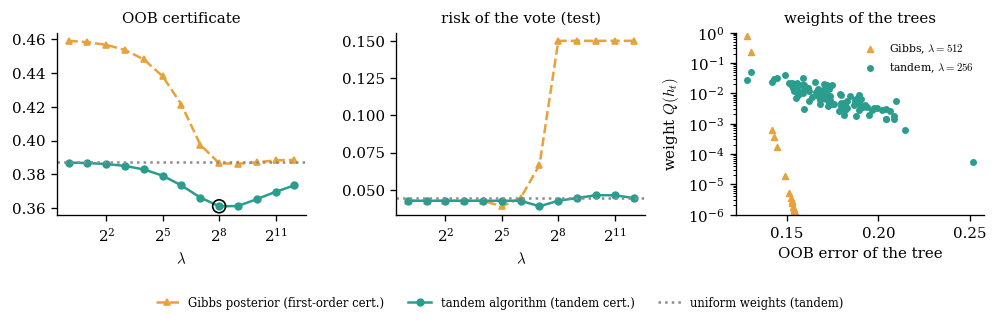

In [20]:
show_figure("tp5_learning")

When $\lambda$ grows, the Gibbs posterior concentrates on the trees with the smallest OOB error: for $\lambda\geq256$ only one or two effective trees remain, and the vote loses its diversity: its test risk jumps from $0.044$ to $0.150$, although its first-order certificate decreases (from $0.460$ to $0.386$). The tandem algorithm concentrates much more slowly: for the selected $\lambda=256$ it keeps $57$ effective trees, certifies the vote at $0.361$ instead of $0.387$ for the uniform weights, and its test risk stays at $0.043$ (right panel: the weights decrease smoothly with the OOB error of the trees, instead of selecting the two best ones). This is the algorithm of Section 17, and we recover its numbers. The iterations converge in about $130$ steps; for $\lambda=2048$ they converge slowly and for $\lambda=4096$ they do not converge within $3000$ iterations (the step $\alpha=0.1$ becomes too large), which does not matter for the validity of the certificate (question 5).

**5.** The kl tandem certificate (15.4) holds with probability $1-\delta$ *simultaneously for all* posteriors. It holds in particular for every $Q_\lambda$, and for the one with the smallest certificate, whatever the rule used to choose it: $\lambda$ only indexes posteriors, it is not a parameter of the bound (unlike in Proposition 17.1, see Part 5). For the same reason the certificate remains valid if the iterations are stopped early: the certificate is computed for the posterior actually returned, whatever its quality.

**6.** Uniform weights, Gibbs posterior and tandem algorithm, $\lambda$ selected on the corresponding certificate:

In [21]:
show_table("p4_datasets")

| data | uniform – vote (test) | uniform – tandem cert. | Gibbs posterior – vote (test) | Gibbs posterior – FO cert. | Gibbs posterior – eff. trees | tandem algorithm – vote (test) | tandem algorithm – tandem cert. | tandem algorithm – eff. trees |
|:---:|:---:|:---:|:---:|:---:|:---:|:---:|:---:|:---:|
| spambase | 0.054 | 0.290 | 0.095 | 0.269 | 2.1 | 0.054 | 0.274 | 50.4 |
| wdbc | 0.053 | 0.482 | 0.047 | 0.282 | 9.9 | 0.053 | 0.440 | 37.4 |
| australian | 0.155 | 0.812 | 0.217 | 0.508 | 1.1 | 0.140 | 0.764 | 46.1 |

On the three datasets, the Gibbs posterior selected on its first-order certificate keeps very few trees ($1$ to $10$ effective trees), and its vote is worse than the forest on `spambase` ($0.095$ against $0.054$) and `australian` ($0.217$ against $0.155$), even when its first-order certificate is the smallest of the table (`spambase`, `wdbc`, `australian`): a good certificate for the Gibbs classifier is not a good vote. The tandem algorithm keeps $37$ to $50$ effective trees, a vote as good as the forest (better on `australian`), and a certificate slightly better than the uniform weights. On small datasets (`wdbc` and `australian`: $398$ and $483$ training examples, hence common OOB sets of $126$ and $156$ examples only) all the certificates are loose. To learn a vote, the objective must contain a second-order term, such as the joint error: *choosing a bound is choosing an inductive bias* (Section 17.6).

## Part 5 – Going further $(\star)$

1.  **The factor 2 cannot be improved.** Take $n$ voters ($n$ odd) with uniform weights, a set $A$ of inputs of probability $\frac{2rn}{n+1}$ on which exactly $\frac{n+1}2$ voters err, and no error outside $A$.\
    Compute $R_{\mathcal{D}}(G_{Q})$, $e_{\mathcal{D}}(Q)$, $R_{\mathcal{D}}(B_{Q})$, the ratio $R_{\mathcal{D}}(B_{Q})/R_{\mathcal{D}}(G_{Q})$ and the tandem bound for $n\in\{3,11,101\}$, $r\in\{0.05,0.2\}$.\
    Conclude.

2.  **The C-bound.** Using the Chebyshev--Cantelli inequality $\mathbb{P}(Z-\mathbb{E}Z\geq a)\leq\frac{\mathrm{Var}Z}{\mathrm{Var}Z+a^2}$ for the margin $M_Q=1-2W_Q$ (Section 15.6), prove the C-bound $R_{\mathcal{D}}(B_{Q})\leq1-\frac{(1-2R_{\mathcal{D}}(G_{Q}))^2}{1-2d_{\mathcal{D}}(Q)}$ when $R_{\mathcal{D}}(G_{Q})<\frac12$. Add it to the figure of Part 2, question 5.

3.  **Convexity.** When all the voters are evaluated on the same examples $x_1,\dots,x_m$, show that $\hat e(Q)=\frac1m\sum_iW_Q(x_i)^2$, and deduce that $F_\lambda$ is convex, so that the fixed point of Algorithm 13 is its global minimum.

4.  **The linear certificate.** For the posterior selected in Part 4, compute the linear tandem certificate of Proposition 17.1 with the union bound over the $13$ values of $\lambda$ ($\ln\frac{13}\delta$ instead of $\ln\frac1\delta$) and compare it with the kl certificate. Why is it looser?

In [22]:
def part5(F, best):
    print("Part 5")
    rows = []
    for n_voters in [3, 11, 101]:
        for r in [0.05, 0.2]:
            pA = 2 * r * n_voters / (n_voters + 1)
            gibbs = pA * (n_voters + 1) / (2 * n_voters); vote = pA
            joint = pA * ((n_voters + 1) / (2 * n_voters)) ** 2
            rows.append(f"{n_voters} & {r} & {gibbs:.3f} & {joint:.3f} & {vote:.3f} & {vote / gibbs:.3f} & {min(1, 4 * joint):.3f}")
    keep_table("p5_tight", rows)
    # C-bound added to the figure of Part 2
    n = 25; cs = np.linspace(0, 0.98, 99)
    fig, axes = plt.subplots(1, 3, figsize=(7.6, 2.5), sharey=True)
    for ax, p in zip(axes, [0.2, 0.35, 0.45]):
        Qs = [exact_quantities(n, p, c) for c in cs]
        ax.plot(cs, [q[3] for q in Qs], color="k", lw=1.8, label="risk of the vote")
        ax.plot(cs, np.minimum(1, [2 * q[0] for q in Qs]), color=C1, label="first order")
        ax.plot(cs, np.minimum(1, [4 * q[1] for q in Qs]), color=C2, label="tandem")
        ax.plot(cs, [c_bound(q[0], q[2]) for q in Qs], color=C3, ls="--", label="C-bound")
        ax.set_title(rf"$p={p}$", fontsize=9); ax.set_xlabel(r"correlation $c$"); ax.set_ylim(0, 1)
    axes[1].legend(fontsize=7, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.27))
    keep_figure(fig, "tp5_cbound")
    # linear tandem certificate (Proposition 17.1) with a union bound over the 13 values of lambda
    P = np.ones(100) / 100; Q, lam = best["Qt"], best["lam"]; e = Q @ F["E"] @ Q; KLq = kl_div(Q, P); m = F["m"]
    lin = 4 * (e + (2 * KLq + np.log(len(LAMBDAS) / DELTA)) / lam + lam / (8 * m))
    lam_opt = min(LAMBDAS, key=lambda l: 4 * (e + (2 * KLq + np.log(len(LAMBDAS) / DELTA)) / l + l / (8 * m)))
    lin_opt = 4 * (e + (2 * KLq + np.log(len(LAMBDAS) / DELTA)) / lam_opt + lam_opt / (8 * m))
    keep_table("p5_linear", [f"selected $\\lambda$ & {lam}", f"$\\hat e(Q)$ & {e:.4f}", f"$\\mathrm{{KL}}(Q\\|P)$ & {KLq:.3f}",
                             f"linear certificate, $\\lambda={lam}$, $\\ln\\frac{{13}}{{\\delta}}$ & {lin:.3f}",
                             f"linear certificate, best $\\lambda$ of the grid ({lam_opt}) & {lin_opt:.3f}",
                             f"kl certificate (Part 4) & {best['tnd']:.3f}"])

In [23]:
part5(F, best)

Part 5


### Solution

**1.** On $A$ the proportion of erring voters is $\frac{n+1}{2n}>\frac12$, so the vote errs exactly on $A$: $R_{\mathcal{D}}(B_{Q})=\mathbb{P}(A)=\frac{2rn}{n+1}$, $R_{\mathcal{D}}(G_{Q})=\mathbb{P}(A)\frac{n+1}{2n}=r$ and $e_{\mathcal{D}}(Q)=\mathbb{P}(A)\big(\frac{n+1}{2n}\big)^2$.

In [24]:
show_table("p5_tight")

| $n$ | $r$ | $R_{\mathcal{D}}(G_Q)$ | $e(Q)$ | $R_{\mathcal{D}}(B_Q)$ | ratio | $4e(Q)$ |
|:---:|:---:|:---:|:---:|:---:|:---:|:---:|
| 3 | 0.05 | 0.050 | 0.033 | 0.075 | 1.500 | 0.133 |
| 3 | 0.2 | 0.200 | 0.133 | 0.300 | 1.500 | 0.533 |
| 11 | 0.05 | 0.050 | 0.027 | 0.092 | 1.833 | 0.109 |
| 11 | 0.2 | 0.200 | 0.109 | 0.367 | 1.833 | 0.436 |
| 101 | 0.05 | 0.050 | 0.025 | 0.099 | 1.980 | 0.101 |
| 101 | 0.2 | 0.200 | 0.101 | 0.396 | 1.980 | 0.404 |

The ratio $\frac{2n}{n+1}$ tends to $2$: the first-order bound is tight in the worst case, when, on the points where the vote errs, a bare majority of voters errs and they are all right elsewhere. In this case the tandem bound is also almost tight ($4e(Q)\to R_{\mathcal{D}}(B_{Q})$), since $W_Q$ only takes the values $0$ and $\approx\frac12$.

**2.** $B_{Q}$ errs iff $M_Q\leq0$. We have $\mathbb{E}M_Q=1-2R_{\mathcal{D}}(G_{Q})>0$ and $\mathbb{E}M_Q^2=1-4R_{\mathcal{D}}(G_{Q})+4e_{\mathcal{D}}(Q)=1-2d_{\mathcal{D}}(Q)$ by the identity of Part 2, so $\mathrm{Var}M_Q=1-2d_{\mathcal{D}}(Q)-(1-2R_{\mathcal{D}}(G_{Q}))^2$. Chebyshev–Cantelli applied to $Z=-M_Q$ with $a=\mathbb{E}M_Q$ gives $$R_{\mathcal{D}}(B_{Q})\leq\mathbb{P}\big(-M_Q+\mathbb{E}M_Q\geq\mathbb{E}M_Q\big)\leq\frac{\mathrm{Var}M_Q}{\mathrm{Var}M_Q+(\mathbb{E}M_Q)^2}=1-\frac{(1-2R_{\mathcal{D}}(G_{Q}))^2}{1-2d_{\mathcal{D}}(Q)}.$$ The C-bound is small when the Gibbs risk is small *and* the disagreement is large: it formalizes the accuracy–diversity trade-off of TP 2.

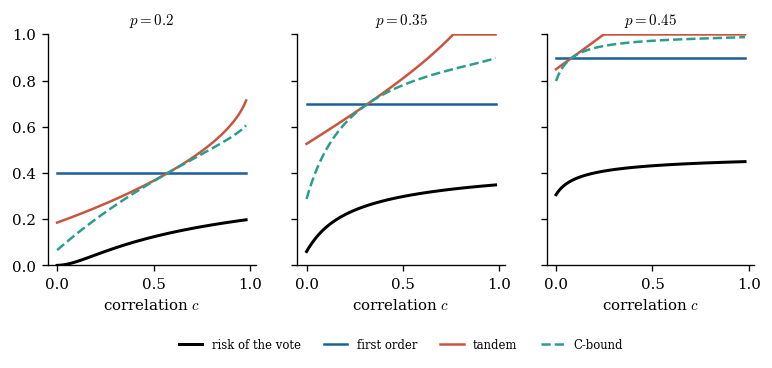

In [25]:
show_figure("tp5_cbound")

For weakly correlated voters the C-bound is by far the tightest of the three; for strongly correlated voters it degrades too. Its PAC-Bayesian version needs two estimates (the Gibbs risk and the disagreement), hence a union bound, which makes it less attractive in practice (Section 15.5).

**3.** If all the voters are evaluated on $x_1,\dots,x_m$, $\hat e(h,h')=\frac1m\sum_i\mathbb{1}\left[h(x_i)\neq y_i\right]\mathbb{1}\left[h'(x_i)\neq y_i\right]$, so $\hat e(Q)=\frac1m\sum_i\big(\sum_hQ(h)\mathbb{1}\left[h(x_i)\neq y_i\right]\big)^2=\frac1m\sum_iW_Q(x_i)^2$. Each $W_Q(x_i)$ is a linear function of $Q$, its square is convex, so $\hat e$ is convex; the KL is convex in $Q$; hence $F_\lambda$ is convex on the simplex, and a point that satisfies the optimality condition of question 3 of Part 4 is its global minimum. With the OOB examples, the pairs are evaluated on different examples and convexity is not guaranteed (the table of joint errors may have slightly negative eigenvalues), but the iterations converge in practice.

**4.**

In [26]:
show_table("p5_linear")

|  | value |
|:---:|:---:|
| selected $\lambda$ | 256 |
| $\hat e(Q)$ | 0.0420 |
| $\mathrm{KL}(Q\Vert P)$ | 0.317 |
| linear certificate, $\lambda=256$, $\ln\frac{13}{\delta}$ | 0.568 |
| linear certificate, best $\lambda$ of the grid (128) | 0.513 |
| kl certificate (Part 4) | 0.361 |

The linear certificate is much looser ($0.51$ at best against $0.361$). It pays $\ln\frac{13}\delta$ for the choice of $\lambda$ in the grid, and above all its term $\frac{\lambda}{8m}$, inherited from Hoeffding's lemma, does not adapt to the small value of $\hat e(Q)$: its optimum over $\lambda$ costs $2\sqrt{(2\operatorname{KL}+\ln(13/\delta))/(8m)}\approx0.086$ inside the factor $4$ (about $0.34$ on the certificate) whatever $\hat e(Q)$, while the kl bound adapts to small values, like the kl test-set bound of TP 4. This is why the linear bound is used to *design* the algorithm, and the kl bound to *certify* its output (Section 17.5).